# disordered Floquet: 10 qubits and 50 disorder realizations per depth

This notebook follows the same structure as the natural thermalization notebook. The sweep loops over **1, 5, 10, 15, 20, 25, 30, 35, 40, 45, and 50 layers**. Each depth averages **50 disorder realizations**, with **1024 shots per circuit**. Every circuit starts in $|0\rangle^{\otimes 10}$.

One layer (one Floquet period $U_F$) consists of the same six rows as before:

1. RX rotations on all 10 qubits
2. RZZ gates on (0,1), (2,3), (4,5), (6,7), (8,9)
3. RZZ gates on (1,2), (3,4), (5,6), (7,8), with qubits 0 and 9 idle for this row
4. RY rotations on all 10 qubits
5. the same even-pair RZZ row as step 2
6. the same odd-pair RZZ row as step 3

The C_zz interactions use RZZ(π/4). The only change from natural thermalization is **where the randomness lives**:

| circuit | within one layer | between layers |
|---|---|---|
| clean Floquet | every qubit gets the same RX angle and the same RY angle | identical |
| **disordered Floquet (this notebook)** | every qubit gets its own random RX and RY angle | **identical** |
| natural thermalization | every qubit gets its own random RX and RY angle | fresh angles every layer |

For each disorder realization $j$, the angles $\theta^{x}_{j,q}, \theta^{y}_{j,q}$ are drawn once, independently and uniformly from −π/4 to +π/4 for every qubit $q$. That one layer $U_F^{(j)}$ is then repeated, so an $L$-layer circuit is $\big(U_F^{(j)}\big)^L$. The same 50 realizations are reused at every depth, so each point on the plot follows the same 50 disordered systems further in time.

Only qubit 0 is measured, after the final layer. Each circuit's estimate is

$$\langle Z_0\rangle_j \approx \frac{N_{0,j}-N_{1,j}}{1024}.$$

`circuit_counts` stores the counts, `circuit_expectation_values` stores all 50 estimates per depth, and `results` stores their arithmetic mean:

$$\overline{\langle Z_0\rangle} = \frac{1}{50}\sum_{j=1}^{50}\langle Z_0\rangle_j.$$

The first realization's 1-layer and 5-layer circuits are displayed; in the 5-layer drawing every layer has the same angles. The plot starts at **(0 layers, 1)**, the exact expectation value of the initial all-zero state.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler

n_qubits = 10
shots = 1024
n_disorder_realizations = 50
layer_values = [1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
seed = 2026
rotation_limit = np.pi / 4 #maximum rx and ry angle in radians
entangling_angle = np.pi / 4 #rzz interaction angle

plotting function below

In [2]:
#----- plotting: same function as the natural thermalization notebook -----

def plot_expectation_values(
    depths,
    values,
    placeholder=True,
    output_path="disordered_floquet_plot.png",
    label="Mean of 50 disordered Floquet circuits",
    title="Disordered Floquet: Mean Pauli-Z Expectation Value vs. Number of Layers",
):
    depths = np.asarray(depths, dtype=float)
    values = np.asarray(values, dtype=float)

    if depths.ndim != 1 or values.ndim != 1:
        raise ValueError("Depths and expectation values must be 1D arrays.")

    if len(depths) == 0 or len(depths) != len(values):
        raise ValueError("Provide the same nonzero number of depths and values.")

    if not np.all(np.isfinite(depths)) or not np.all(np.isfinite(values)):
        raise ValueError("All data must contain finite numbers.")

    if np.any(depths < 0):
        raise ValueError("Circuit depths cannot be negative.")

    if np.any((values < -1) | (values > 1)):
        raise ValueError("Pauli-Z expectation values must be between -1 and 1.")

    #arrange points in increasing circuit-depth order.
    order = np.argsort(depths)
    depths = depths[order]
    values = values[order]

    fig, ax = plt.subplots(figsize=(9, 5)) #creates a graph and a set of subplots with a specified size

    #--- this is all graph styling and labeling, not quantum-circuit code. ---
    #draws data points and connects them with lines
    ax.plot(
        depths,
        values,
        color="#0099AB",
        linewidth=2,
        marker="o",
        markersize=4,
        label="Synthetic placeholder data" if placeholder else label,
    )

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)

    ax.set_xlabel("Number of layers (Floquet periods)", fontsize=12)
    ax.set_ylabel(
        r"Mean Pauli-$Z$ expectation value $\langle Z_0\rangle$",
        fontsize=12,
    )
    ax.set_title("Illustrative Relaxation — Placeholder Data" if placeholder else title)

    ax.set_xlim(left=0)
    ax.set_ylim(-1.05, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

## build one Floquet layer per disorder realization

Each realization draws its 10 RX angles and 10 RY angles **once**. `floquet_layers[j]` is that fixed layer; the sweep below stacks copies of it, so the angles never change from one layer to the next.

In [3]:
#draw the disorder once: one row of angles per realization, one column per qubit
disorder_rng = np.random.default_rng(seed)
rx_angles = disorder_rng.uniform(-rotation_limit, rotation_limit, size=(n_disorder_realizations, n_qubits))
ry_angles = disorder_rng.uniform(-rotation_limit, rotation_limit, size=(n_disorder_realizations, n_qubits))


def build_floquet_layer(rx, ry):
    #one period U_F: random-but-fixed rotations, then even and odd rzz rows, twice
    layer = QuantumCircuit(n_qubits)
    for angles, rotate in ((rx, layer.rx), (ry, layer.ry)):
        for q in range(n_qubits):
            rotate(angles[q], q) #each qubit has its own angle (disorder within the layer)
        layer.barrier()

        #after each rotation stage, apply even pairs and then odd pairs
        for start in (0, 1):
            for q in range(start, n_qubits - 1, 2):
                layer.rzz(entangling_angle, q, q + 1)
            layer.barrier()
    return layer


floquet_layers = [
    build_floquet_layer(rx_angles[j], ry_angles[j]) for j in range(n_disorder_realizations)
]

print(f"built {len(floquet_layers)} Floquet layers, {floquet_layers[0].size()} operations each")
print("realization 0 rx angles:", np.round(rx_angles[0], 3))
print("realization 0 ry angles:", np.round(ry_angles[0], 3))

built 50 Floquet layers, 38 operations each
realization 0 rx angles: [-0.504  0.22  -0.051 -0.203 -0.228  0.456  0.636 -0.507  0.24  -0.317]
realization 0 ry angles: [ 0.583 -0.367  0.619 -0.305 -0.695 -0.33  -0.181 -0.623 -0.11   0.468]


## sweep over circuit layers

Run setup, the plotting-function cell, and the layer cell first, then run this cell once to calculate every depth in `layer_values`. Each depth uses the same 50 disorder realizations, repeated `layers` times. Rerunning the sweep clears the previous results and restores the initial point (0, 1).

1 layer(s): mean <Z_0> = +0.800898 over 50 disorder realizations, 1024 shots each


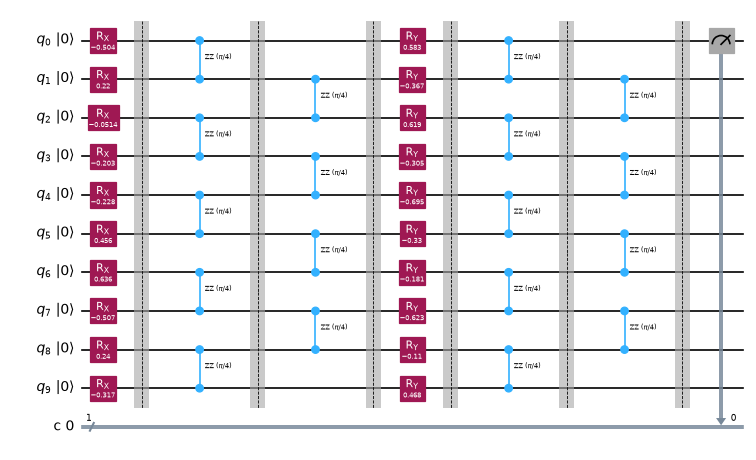

5 layer(s): mean <Z_0> = +0.782969 over 50 disorder realizations, 1024 shots each


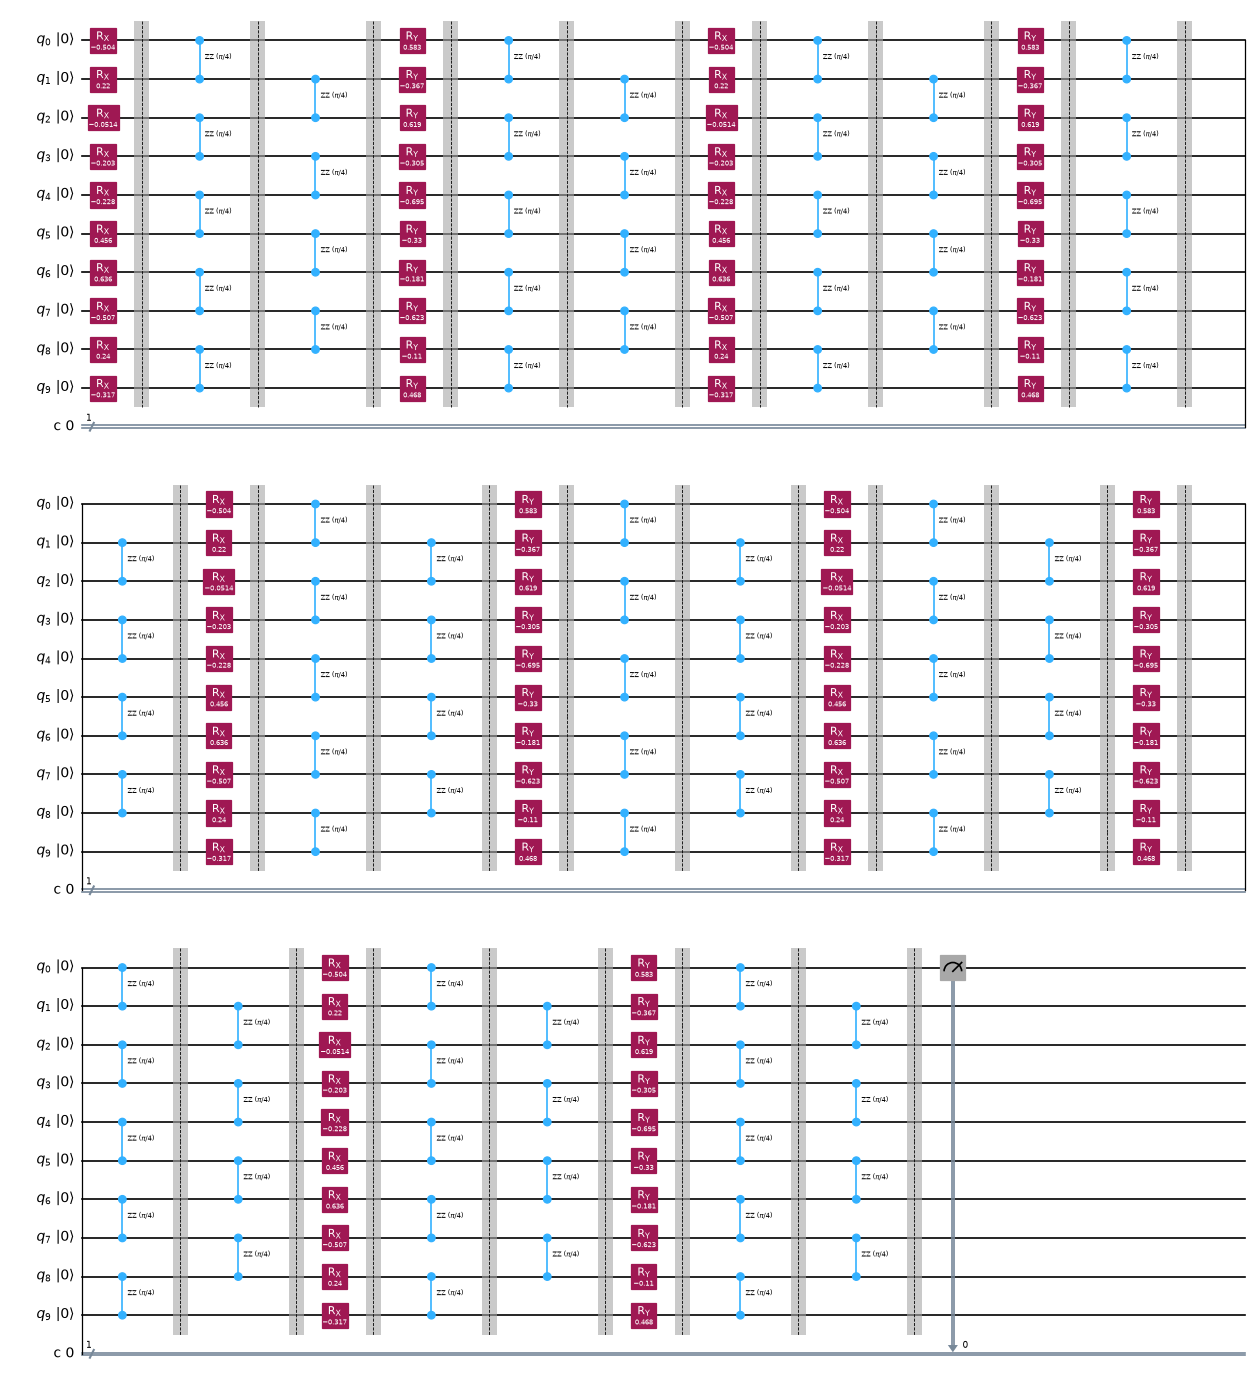

10 layer(s): mean <Z_0> = +0.800469 over 50 disorder realizations, 1024 shots each
15 layer(s): mean <Z_0> = +0.830273 over 50 disorder realizations, 1024 shots each
20 layer(s): mean <Z_0> = +0.765312 over 50 disorder realizations, 1024 shots each
25 layer(s): mean <Z_0> = +0.807617 over 50 disorder realizations, 1024 shots each
30 layer(s): mean <Z_0> = +0.824219 over 50 disorder realizations, 1024 shots each
35 layer(s): mean <Z_0> = +0.789844 over 50 disorder realizations, 1024 shots each
40 layer(s): mean <Z_0> = +0.780703 over 50 disorder realizations, 1024 shots each
45 layer(s): mean <Z_0> = +0.826406 over 50 disorder realizations, 1024 shots each
50 layer(s): mean <Z_0> = +0.803711 over 50 disorder realizations, 1024 shots each


In [4]:
if not layer_values or any(type(depth) is not int or depth < 1 for depth in layer_values):
    raise ValueError("layer_values must contain positive integers starting from 1")

#reset the stored results whenever the sweep is rerun
results = {0: 1.0} #the initial all-zero state has z expectation value 1
circuit_expectation_values = {} #all 50 measured z estimates at each depth
circuit_counts = {} #measurement counts for every disorder realization
sample_circuits = {} #realization 0 for the 1-layer and 5-layer cases

for layers in layer_values:
    circuits = []

    for realization in range(n_disorder_realizations):
        qc = QuantumCircuit(n_qubits, 1) #fresh all-zero state for each circuit

        for layer_index in range(layers):
            #repeat the identical Floquet layer: no new angles between layers
            qc.compose(floquet_layers[realization], inplace=True)

        qc.measure(0, 0) #measure qubit 0 only after the final layer
        circuits.append(qc)

    #advance the shot rng across circuits instead of restarting the same samples
    sampler = StatevectorSampler(seed=np.random.default_rng(seed + layers))
    sampled_results = sampler.run(circuits, shots=shots).result()
    counts = [sample.data.c.get_counts() for sample in sampled_results]
    z_values = np.array([
        (c.get("0", 0) - c.get("1", 0)) / shots for c in counts
    ])
    circuit_counts[layers] = counts
    circuit_expectation_values[layers] = z_values
    results[layers] = float(np.mean(z_values))

    print(f"{layers} layer(s): mean <Z_0> = {results[layers]:+.6f} "
          f"over {n_disorder_realizations} disorder realizations, {shots} shots each")

    if layers in (1, 5):
        #display realization 0 at these two depths
        sample_circuits[layers] = circuits[0]
        fig = sample_circuits[layers].draw(output="mpl", fold=30, scale=0.6, initial_state=True)
        display(fig)
        plt.close(fig)

## plot the averaged values

Use the plotting function with the mean of 50 disorder realizations at each depth, plus the exact initial point (0 layers, 1). To change the depths, edit `layer_values` in setup, then rerun setup, the layer cell, the sweep, and this plotting cell.

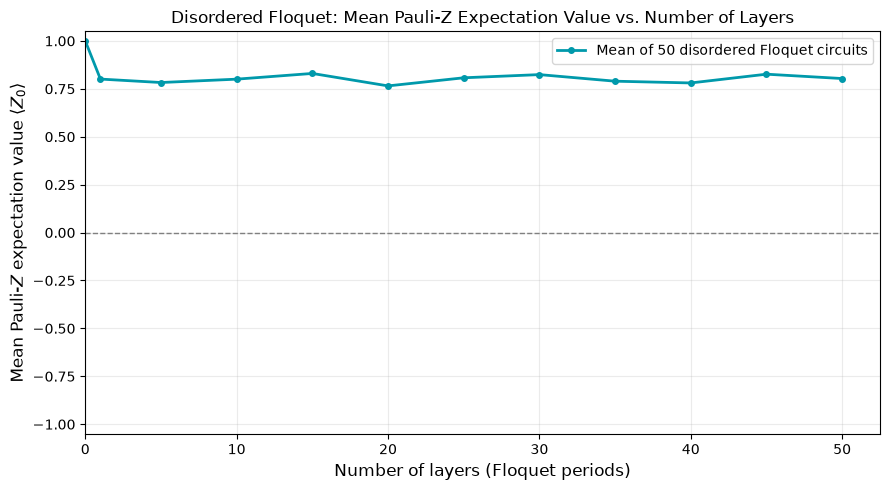

In [5]:
#plot the stored means together with the initial zero-layer value
circuit_depths = np.array(sorted(results))
expectation_values = np.array([results[depth] for depth in circuit_depths])
using_placeholder_data = False

plot_expectation_values(
    circuit_depths,
    expectation_values,
    placeholder=using_placeholder_data,
)